# 9. Link Prediction

Wir vergleichen vier Netzwerkverfahren mit drei attributbasierten Faustregeln.
Trainiert wird auf Veranstaltungstagen von **2016 bis 2019**, getestet auf **2021 bis 2025**.
Das Jahr 2020 bleibt vollständig ausgeschlossen. Der Kern umfasst Athleten mit mindestens
drei verschiedenen Veranstaltungstagen in **beiden** Zeiträumen. Die Hauptanalyse ist daher
ein **retrospektiver Vergleich einer im Nachhinein definierten aktiven Population**.

Die zeitliche Core-Evaluation und die Top-$K$-Auswahl folgen dem Experiment von
[Liben-Nowell und Kleinberg](https://www.cs.cornell.edu/home/kleinber/link-pred.pdf).
Die Vorgaben zu SAN Kapitel 12.2 stammen aus dem Aufgabenprompt. Das SAN-Skript selbst
lag für diese Implementierung nicht vor. Ein Veranstaltungstag ist die vorhandene
Kombination aus Wettkampfname, Ort, Datum und Beckenlänge, identifiziert durch `event_id`.
Er ist nicht mit einem blossen Kalendertag gleichzusetzen.

Alle Berechnungen in diesem Notebook sind exakt. Es werden keine früheren Analyse-Notebooks
ausgeführt. Zwei zusätzliche Analysen prüfen wiederholte Testverbindungen und eine nur
anhand des Trainings ausgewählte Kernpopulation.

In [1]:
from pathlib import Path
import gc
import hashlib
import importlib.metadata
import json
import sys

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter
import networkx as nx
import numpy as np
import pandas as pd
from scipy import sparse
from IPython.display import display, Markdown
from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")

PROJECT_ROOT = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT / 'Notebooks'))
from link_prediction_utils import (
    temporal_split, core_nodes, project_events, candidate_pairs,
    network_scores, attribute_scores, evaluate_scores, tie_sensitivity,
)

EVENTS_PATH = PROJECT_ROOT / 'data/processed/networks/athlete_events.parquet'
ATTRIBUTES_PATH = PROJECT_ROOT / 'data/processed/assortativitaet/athlete_attributes.parquet'
RESULT_DIR = PROJECT_ROOT / 'data/processed/link_prediction'
REPORT_DIR = PROJECT_ROOT / 'Report/graphics'
RESULT_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)
SEED = 42
TIE_SEEDS = tuple(range(42, 52))
MIN_EVENTS = 3
BLOCK_SIZE = 256
METHODS = ['common_neighbours', 'adamic_adar', 'preferential_attachment',
           'soundarajan_hopcroft', 'same_nation', 'birth_year', 'nation_birth_year']
LABELS = ['Common Neighbours', 'Adamic-Adar', 'Preferential Attachment',
          'Soundarajan-Hopcroft', 'Gleiche Nation', 'Ähnlicher Jahrgang', 'Nation + Jahrgang']
SHORT_LABELS = ['Common\nNeighbours', 'Adamic-\nAdar', 'Preferential\nAttachment',
                'Soundarajan-\nHopcroft', 'Gleiche\nNation', 'Ähnlicher\nJahrgang', 'Nation +\nJahrgang']
COLOR, ORANGE, MUTED = '#367da2', '#eb6834', '#a3a29d'
REPORT_RC = {'font.size': 8, 'axes.titlesize': 9, 'axes.labelsize': 8,
             'xtick.labelsize': 7, 'ytick.labelsize': 7, 'pdf.fonttype': 42}
plt.rcParams.update({
    'figure.dpi': 110, 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e5e4e0', 'grid.linewidth': 0.8,
    'axes.axisbelow': True, 'axes.edgecolor': '#52514e',
    'axes.labelcolor': '#52514e', 'xtick.color': '#52514e', 'ytick.color': '#52514e',
})

def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

input_hashes = {str(p.relative_to(PROJECT_ROOT)): sha256(p)
                for p in [EVENTS_PATH, ATTRIBUTES_PATH]}

## 9.1 Zeitliche Aufteilung prüfen

Jede Athlet-Veranstaltungstag-Zuordnung zählt einmal. Doppelte Zuordnungen werden entfernt,
widersprüchliche Daten je `event_id` oder fehlende Kennungen werden abgelehnt. Die Intervalle
sind links eingeschlossen und rechts offen, also bis zum 1. Januar des Folgejahrs.

Aus dem Attributexport werden ausschliesslich **Profilnation und Geburtsjahr** eingelesen.
FINA-Punkte und das Jahr der besten Leistung gehen in keinen Score ein. Die Profilnation
stammt aus dem Datenstand 2025 und kann gegenüber 2016 bis 2019 gewechselt haben.

In [2]:
raw_events = pd.read_parquet(EVENTS_PATH)
assert raw_events['athlete_node'].eq('athlete_' + raw_events['athlete_id'].astype(str)).all()
event_key = ['best_name', 'city', 'best_date', 'course']
assert raw_events.groupby('event_id')[event_key].nunique(dropna=False).le(1).all().all()
assert not raw_events[['event_id', *event_key]].drop_duplicates().duplicated(event_key).any()
train, test, split_audit = temporal_split(raw_events)
attributes = pd.read_parquet(ATTRIBUTES_PATH, columns=['nation', 'birth_year'])
assert attributes.index.is_unique and attributes.index.notna().all()
assert set(train['athlete_node']).union(test['athlete_node']) <= set(attributes.index)
core = core_nodes(train, test, min_events=MIN_EVENTS)
training_core = core_nodes(train, min_events=MIN_EVENTS, training_only=True)
train_counts = train.groupby('athlete_node')['event_id'].nunique()
test_counts = test.groupby('athlete_node')['event_id'].nunique()
period_summary = pd.DataFrame([
    {'period': name, 'athletes': frame['athlete_node'].nunique(),
     'event_days': frame['event_id'].nunique(), 'participations': len(frame),
     'first_date': str(frame['best_date'].min().date()),
     'last_date': str(frame['best_date'].max().date())}
    for name, frame in [('training_2016_2019', train), ('test_2021_2025', test)]
])
display(period_summary)
display(pd.Series(split_audit, name='Datenprüfung'))
display(attributes.loc[core].isna().sum().rename('Fehlende Werte im Hauptkern'))
print(f'Kern beider Zeiträume: {len(core):,}; nur Training: {len(training_core):,}')

,period,athletes,event_days,participations,first_date,last_date
0,training_2016_2019,7024,14748,56703,2016-01-03,2019-12-30
1,test_2021_2025,6062,14662,67601,2021-01-04,2025-04-08


input_rows              238942
unique_rows             238942
duplicates_removed           0
excluded_2020_rows        5749
outside_windows_rows    108889
train_rows               56703
test_rows                67601
train_athletes            7024
test_athletes             6062
train_event_days         14748
test_event_days          14662
Name: Datenprüfung, dtype: int64

nation        0
birth_year    0
Name: Fehlende Werte im Hauptkern, dtype: int64

Kern beider Zeiträume: 3,017; nur Training: 5,594


## 9.2 Zwei unabhängige Projektionen und Trainingscommunities

Die Trainingsprojektion enthält **alle** im Trainingszeitraum beobachteten Athleten,
einschliesslich der Personen ausserhalb des Kerns. Eine Kante besteht bereits bei einem
gemeinsamen Veranstaltungstag. Anders als im Arbeitsnetz mit Mindestgewicht 2 würden wir
sonst bereits beobachtete Verbindungen fälschlich als neue Kandidaten behandeln.

Eine dünn besetzte Inzidenzmatrix $B$ liefert die Gewichte über $BB^T$. Die Diagonale wird
entfernt. Train und Test werden getrennt projiziert. Für die Nachbarschaften und Louvain
nutzen wir die **ungewichtete Trainingsprojektion** mit Seed 42 und Auflösung 1.
Die Communities aus Kapitel 5 werden nicht eingelesen. Die neuen Labels `T1`, `T2`, ...
haben keine Beziehung zu `C1` bis `C4`.

In [3]:
train_nodes, train_weights = project_events(train)
train_index = pd.Index(train_nodes)
A = train_weights.copy()
A.data[:] = 1
test_nodes, test_weights = project_events(test)
test_index = pd.Index(test_nodes)
G_train = nx.from_scipy_sparse_array(A)
partition = sorted(nx.community.louvain_communities(
    G_train, weight=None, resolution=1, seed=SEED), key=lambda group: (-len(group), min(group)))
communities = np.empty(len(train_nodes), dtype=np.int32)
for c, members in enumerate(partition):
    communities[list(members)] = c
modularity = nx.community.modularity(G_train, partition, weight=None)
degrees = np.diff(A.indptr)
train_event_sizes = train.groupby('event_id').size().to_numpy(dtype=np.int64)
test_event_sizes = test.groupby('event_id').size().to_numpy(dtype=np.int64)
assert int(train_weights.sum()) == int((train_event_sizes * (train_event_sizes - 1)).sum())
assert int(test_weights.sum()) == int((test_event_sizes * (test_event_sizes - 1)).sum())
assert (A != A.T).nnz == 0 and A.diagonal().sum() == 0
assert set(train_nodes) == set(train['athlete_node'])
print(f'Training: {len(train_nodes):,} Athleten, {A.nnz // 2:,} Kanten, '
      f'{len(partition)} Communities, Q = {modularity:.4f}')
print(f'Test: {len(test_nodes):,} Athleten, {test_weights.nnz // 2:,} Kanten')

def candidate_test_weights(population, pairs):
    # Testinformationen werden erst nach der Kandidatenauswahl als Zielwerte benutzt.
    positions = test_index.get_indexer(population)
    left, right = positions[pairs[0]], positions[pairs[1]]
    known = (left >= 0) & (right >= 0)
    weights = np.zeros(len(left), dtype=np.int32)
    weights[known] = np.asarray(test_weights[left[known], right[known]]).ravel()
    return weights

core_indices = train_index.get_indexer(core)
pairs = candidate_pairs(A, core_indices)
observed_test_weights = candidate_test_weights(core, pairs)
labels = observed_test_weights >= 1
repeat_labels = observed_test_weights >= 2
main_train_edges = A[core_indices][:, core_indices].nnz // 2
assert len(pairs[0]) == len(core) * (len(core) - 1) // 2 - main_train_edges
assert np.all(pairs[0] < pairs[1])
assert not np.asarray(A[core_indices[pairs[0]], core_indices[pairs[1]]]).any()
actual = pd.Series({'core_athletes': len(core), 'training_core_edges': main_train_edges,
                   'candidate_pairs': len(labels), 'new_test_edges': int(labels.sum()),
                   'repeated_new_test_edges': int(repeat_labels.sum())})
expected = pd.Series({'core_athletes': 3017, 'training_core_edges': 50792,
                     'candidate_pairs': 4498844, 'new_test_edges': 121753,
                     'repeated_new_test_edges': 32636})
validation = pd.DataFrame({'actual': actual, 'preliminary': expected, 'difference': actual - expected})
display(validation)
if validation['difference'].ne(0).any():
    raise ValueError('Abweichung von der Vorprüfung. Eingabedaten und Datumszuordnung untersuchen.')
print(f'Zufallspräzision Hauptanalyse: {labels.mean():.6%}; wiederholt: {repeat_labels.mean():.6%}')

Training: 7,024 Athleten, 260,719 Kanten, 224 Communities, Q = 0.5357
Test: 6,062 Athleten, 387,049 Kanten


,actual,preliminary,difference
core_athletes,3017,3017,0
training_core_edges,50792,50792,0
candidate_pairs,4498844,4498844,0
new_test_edges,121753,121753,0
repeated_new_test_edges,32636,32636,0


Zufallspräzision Hauptanalyse: 2.706317%; wiederholt: 0.725431%


## 9.3 Scores ohne Testkanten

Alle Paare bestehen aus zwei verschiedenen, im Training unverbundenen Kernathleten.
Ihre Nachbarschaften reichen über das gesamte Trainingsnetz. Mit den Kernzeilen $A_K$ gelten

| Verfahren | Absteigend sortierter Score |
| --- | --- |
| Common Neighbours | $(A_K A_K^T)_{uv}$ |
| Adamic-Adar | $(A_K\,\mathrm{diag}(1/\ln d_w)\,A_K^T)_{uv}$, Gewicht 0 bei $d_w\leq1$ |
| Preferential Attachment | $d_u d_v$ |
| Soundarajan-Hopcroft | Common Neighbours plus gemeinsame Nachbarn mit $c_u=c_v=c_w$ |
| Gleiche Nation | 1 nur bei zwei bekannten, gleichen Profilnationen, sonst 0 |
| Ähnlicher Jahrgang | Negative absolute Jahrgangsdifferenz |
| Nation + Jahrgang | Zuerst gleiche Nation, innerhalb beider Gruppen kleinere Jahrgangsdifferenz |

Fehlende Jahrgänge erhalten einen Score unterhalb aller bekannten Differenzen. In der
kombinierten Faustregel gilt dies innerhalb der jeweiligen Nationsgruppe. Zwei fehlende
Nationen zählen niemals als gleich. Für den Hauptkern gibt es hier keine fehlenden Werte.
Die Kombination wird durch einen exakt lexikographischen numerischen Score abgebildet.

Die Matrixprodukte werden zeilenweise in Blöcken berechnet. Es entstehen keine dichten
$N\times N$-Matrizen. Bei Soundarajan-Hopcroft müssen **alle drei** Knoten derselben
Trainingscommunity angehören. Automatisierte Tests vergleichen die Implementierung mit
den entsprechenden NetworkX-Funktionen auf kleinen Graphen.

In [4]:
scores = network_scores(A, core_indices, pairs, communities, block_size=BLOCK_SIZE)
scores.update(attribute_scores(attributes.loc[core], pairs))
assert set(scores) == set(METHODS)
assert all(len(s) == len(labels) and np.isfinite(s).all() for s in scores.values())
assert np.all(scores['soundarajan_hopcroft'] >= scores['common_neighbours'])
display(pd.DataFrame({name: {'minimum': float(s.min()), 'maximum': float(s.max()),
                           'zero_share': float(np.mean(s == 0))} for name, s in scores.items()}).T)

,minimum,maximum,zero_share
common_neighbours,0.0,258.000000,0.783145
adamic_adar,0.0,44.525325,0.783145
preferential_attachment,0.0,302451.000000,0.018687
soundarajan_hopcroft,0.0,463.000000,0.783145
same_nation,0.0,1.000000,0.987555
birth_year,-39.0,0.000000,0.075717
nation_birth_year,-39.0,41.000000,0.074878


## 9.4 Top-K-Evaluation und Gleichstände

Die Scores werden vollständig absteigend sortiert. Gleiche Scores werden durch eine
seedabhängige Zufallsreihenfolge aufgelöst. Dieselben Kandidaten bekommen bei allen Verfahren
dieselbe Zufallspriorität. Die zufälligen Prioritäten sind eindeutig.
Es gilt $K=|E_\mathrm{new}|$, $\mathrm{Precision@K}=TP/K$ und
$\mathrm{Faktor}=\mathrm{Precision@K}/(K/|C|)$ mit Kandidatenmenge $C$.
Die Anzahl zukünftiger Kanten ist somit für die Evaluation bekannt und wäre bei einem
echten Einsatz nicht im Voraus verfügbar. Bei diesem $K$ sind Precision und Recall gleich.

Zusätzlich variieren wir ausschliesslich die Tie-Breaking-Seeds von 42 bis 51. Die schnellen
Wiederholungen wählen äquivalent aus der gebundenen Scoregruppe am Cutoff. Sie verändern
weder Scores noch Datenaufteilung. Die Spannweite misst **nur die Tie-Sensitivität** und
ist kein Konfidenzintervall über andere Datensätze oder Zeiträume.

In [5]:
main_results = evaluate_scores(scores, labels, seed=SEED).assign(scenario='main')
repeat_results = evaluate_scores(scores, repeat_labels, seed=SEED).assign(scenario='repeated_test')
ties = pd.concat([
    tie_sensitivity(scores, labels, seeds=TIE_SEEDS).assign(scenario='main'),
    tie_sensitivity(scores, repeat_labels, seeds=TIE_SEEDS).assign(scenario='repeated_test'),
], ignore_index=True)
for result in [main_results, repeat_results]:
    selected = ties[ties['scenario'].eq(result['scenario'].iloc[0]) & ties['seed'].eq(SEED)]
    np.testing.assert_array_equal(result['true_positives'], selected['true_positives'])
display(main_results[['method', 'k', 'true_positives', 'precision_at_k', 'random_precision', 'lift']])
tie_summary = ties.groupby(['scenario', 'method'], sort=False).agg(
    precision_min=('precision_at_k', 'min'), precision_max=('precision_at_k', 'max'),
    lift_min=('lift', 'min'), lift_max=('lift', 'max'))
display(tie_summary.loc['main'])

# Dauerhafter Export aller Hauptkandidaten. core_i/core_j beziehen sich auf core_index
# in training_nodes.parquet. Die ganzzahligen Indizes vermeiden Millionen ID-Strings.
candidate_table = pd.DataFrame({'core_i': pairs[0], 'core_j': pairs[1],
                                'test_days': observed_test_weights, **scores}, copy=False)
candidate_table.to_parquet(RESULT_DIR / 'candidate_scores.parquet', index=False, compression='zstd')
del candidate_table

,method,k,true_positives,precision_at_k,random_precision,lift
0,common_neighbours,121753,17967,0.147569,0.027063,5.452770
1,adamic_adar,121753,19334,0.158797,0.027063,5.867638
2,preferential_attachment,121753,5792,0.047572,0.027063,1.757803
3,soundarajan_hopcroft,121753,20388,0.167454,0.027063,6.187514
4,same_nation,121753,30612,0.251427,0.027063,9.290376
5,birth_year,121753,4575,0.037576,0.027063,1.388458
6,nation_birth_year,121753,31217,0.256396,0.027063,9.473986


,precision_min,precision_max,lift_min,lift_max
method,,,,
common_neighbours,0.147512,0.147709,5.450645,5.457929
adamic_adar,0.158797,0.158797,5.867638,5.867638
preferential_attachment,0.047572,0.047580,1.757803,1.758106
soundarajan_hopcroft,0.167199,0.167610,6.178106,6.193281
same_nation,0.250614,0.251673,9.260331,9.299481
birth_year,0.037420,0.038866,1.382692,1.436105
nation_birth_year,0.256183,0.257250,9.466096,9.505549


## 9.5 Robustheit

**Wiederholte Testverbindungen** verlangen mindestens zwei gemeinsame Veranstaltungstage
im Test. Kandidaten und Trainingsscores bleiben gleich. $K$ und Zufallsbasis werden für
diese neue Zieldefinition separat bestimmt. Ein höherer Faktor wäre deshalb nicht direkt
mit dem Faktor der Hauptanalyse vergleichbar.

**Nur im Training definierter Kern** verlangt mindestens drei Trainingstage, unabhängig
von späterer Aktivität. Personen ohne Testbeobachtung bleiben in der Population. Ihr Fehlen
in diesem Bestleistungsbestand belegt allerdings weder einen Rücktritt noch Nichtteilnahme.
Die grössere Kandidatenmenge verwendet denselben Trainingsgraphen und dieselben
Trainingscommunities. Die Definition entfernt die Selektion anhand der Testaktivität,
aber nicht die Grenzen des rückblickenden Bestleistungsbestands, der Profilnation oder von $K$.

In [6]:
# Hauptarrays vor der grösseren Sensitivitätsanalyse freigeben.
del scores, pairs, observed_test_weights, labels, repeat_labels
gc.collect()
training_indices = train_index.get_indexer(training_core)
training_pairs = candidate_pairs(A, training_indices)
training_labels = candidate_test_weights(training_core, training_pairs) >= 1
training_scores = network_scores(A, training_indices, training_pairs, communities, block_size=BLOCK_SIZE)
training_scores.update(attribute_scores(attributes.loc[training_core], training_pairs))
training_results = evaluate_scores(training_scores, training_labels, seed=SEED).assign(scenario='training_only')
results = pd.concat([main_results, repeat_results, training_results], ignore_index=True)
training_core_edges = A[training_indices][:, training_indices].nnz // 2
split_summary = pd.DataFrame([
    {'scenario': name, 'core_athletes': population, 'training_core_edges': edges,
     'candidate_pairs': int(frame['n_candidates'].iloc[0]), 'new_test_edges': int(frame['k'].iloc[0]),
     'random_precision': float(frame['random_precision'].iloc[0])}
    for name, population, edges, frame in [
        ('main', len(core), main_train_edges, main_results),
        ('repeated_test', len(core), main_train_edges, repeat_results),
        ('training_only', len(training_core), training_core_edges, training_results)]
])
display(split_summary)
display(results.pivot(index='method', columns='scenario', values=['precision_at_k', 'lift']).reindex(METHODS))
del training_scores, training_pairs, training_labels
gc.collect()

,scenario,core_athletes,training_core_edges,candidate_pairs,new_test_edges,random_precision
0,main,3017,50792,4498844,121753,0.027063
1,repeated_test,3017,50792,4498844,32636,0.007254
2,training_only,5594,234125,15409496,129358,0.008395


precision_at_k                                  lift  \
scenario                          main repeated_test training_only      main   
method                                                                         
common_neighbours             0.147569      0.074458      0.028495  5.452770   
adamic_adar                   0.158797      0.100564      0.039000  5.867638   
preferential_attachment       0.047572      0.007783      0.009880  1.757803   
soundarajan_hopcroft          0.167454      0.126701      0.050774  6.187514   
same_nation                   0.251427      0.311864      0.202995  9.290376   
birth_year                    0.037576      0.010541      0.014116  1.388458   
nation_birth_year             0.256396      0.386904      0.225684  9.473986   

                                                     
scenario                repeated_test training_only  
method                                               
common_neighbours           10.263922      3.394354  
adamic_adar                 13.862631      4.645827  
preferential_attachment      1.072854      1.176881  
soundarajan_hopcroft        17.465563      6.048323  
same_nation                 42.990207     24.181322  
birth_year                   1.453000      1.681522  
nation_birth_year           53.334382     26.884097

0

## 9.6 Abbildungen und Ergebnisvergleich

Blau kennzeichnet Netzwerkverfahren und Orange die Faustregeln. Die gestrichelte Linie
zeigt die jeweilige Zufallsbasis. Schwarze Intervalle in der Hauptgrafik zeigen die
Spannweite über zehn Tie-Breaking-Seeds. Werte an den Balken beziehen sich auf Seed 42.
Die zweite Grafik zeigt die absolute Precision@K einschliesslich der beiden Sensitivitäten.

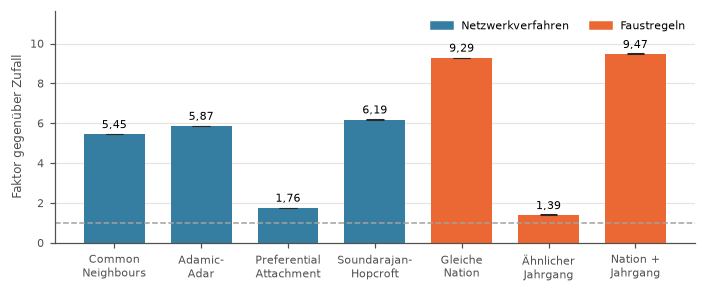

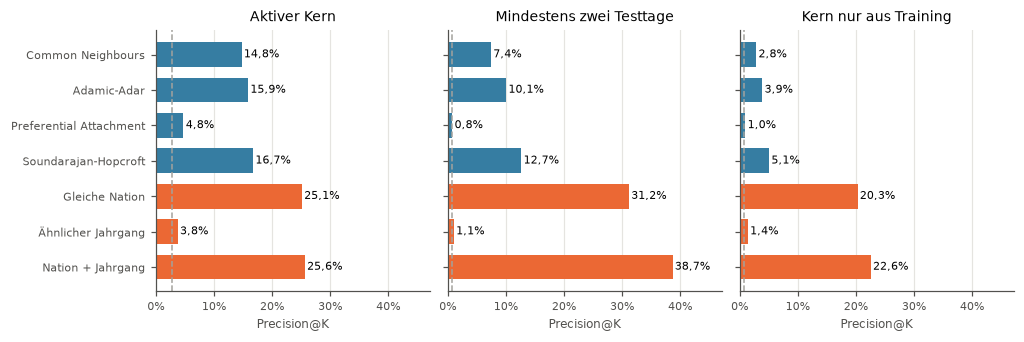

In [7]:
main_ordered = main_results.set_index('method').loc[METHODS]
colors = [COLOR] * 4 + [ORANGE] * 3
x = np.arange(len(METHODS))
with plt.rc_context(REPORT_RC):
    fig, ax = plt.subplots(figsize=(6.3, 2.55), layout='constrained')
    ax.bar(x, main_ordered['lift'], color=colors, width=0.7)
    span = tie_summary.loc['main'].loc[METHODS]
    ax.vlines(x, span['lift_min'], span['lift_max'], color='#292826', linewidth=1.2)
    ax.hlines(span['lift_min'], x - .10, x + .10, color='#292826', linewidth=.7)
    ax.hlines(span['lift_max'], x - .10, x + .10, color='#292826', linewidth=.7)
    for xi, value in zip(x, main_ordered['lift']):
        ax.annotate(f'{value:.2f}'.replace('.', ','), (xi, value), xytext=(0, 4),
                    textcoords='offset points', ha='center', fontsize=7)
    ax.axhline(1, color=MUTED, linestyle='--', linewidth=1)
    ax.set(xticks=x, xticklabels=SHORT_LABELS, ylabel='Faktor gegenüber Zufall',
           ylim=(0, main_ordered['lift'].max() * 1.23))
    ax.grid(axis='x', visible=False)
    ax.legend(handles=[Patch(color=COLOR, label='Netzwerkverfahren'),
                       Patch(color=ORANGE, label='Faustregeln')], frameon=False,
              loc='upper right', ncols=2, fontsize=7)
    fig.savefig(REPORT_DIR / '09_link_prediction.pdf', bbox_inches='tight',
                metadata={'CreationDate': None, 'ModDate': None})
    plt.show()

with plt.rc_context(REPORT_RC):
    fig, axes = plt.subplots(1, 3, figsize=(9.2, 3.0), sharey=True, layout='constrained')
    for ax, scenario, title in zip(axes, ['main', 'repeated_test', 'training_only'],
                                    ['Aktiver Kern', 'Mindestens zwei Testtage', 'Kern nur aus Training']):
        frame = results[results['scenario'].eq(scenario)].set_index('method').loc[METHODS]
        ax.barh(x, frame['precision_at_k'], color=colors, height=.7)
        ax.axvline(frame['random_precision'].iloc[0], color=MUTED, linestyle='--', linewidth=1)
        for yi, value in zip(x, frame['precision_at_k']):
            ax.text(value + .004, yi, f'{value:.1%}'.replace('.', ','), va='center', fontsize=7)
        ax.set(title=title, xlabel='Precision@K', xlim=(0, results['precision_at_k'].max() * 1.22))
        ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
        ax.grid(axis='y', visible=False)
    axes[0].set_yticks(x, LABELS)
    axes[0].invert_yaxis()
    fig.savefig(REPORT_DIR / '09_precision_robustheit.pdf', bbox_inches='tight',
                metadata={'CreationDate': None, 'ModDate': None})
    plt.show()

## 9.7 Einordnung und Grenzen

Die folgende Übersicht berechnet die zentralen Vergleiche direkt aus den Ergebnissen.
Ein Gewinn von Soundarajan-Hopcroft gegenüber Common Neighbours misst den zusätzlichen
Rankingnutzen der **Trainingscommunities**. Er testet nicht die Existenz der Communities
aus Kapitel 5. Preferential Attachment misst das Produkt der Grade und beweist keinen
kausalen Mechanismus. Ein grosser Degree kann schon durch wenige grosse Wettkämpfe entstehen.

Die hohe Jahrgangsassortativität von 0,85 und die Degree-Assortativität von 0,40 in Kapitel 8
betreffen das gesamte historische Arbeitsnetz. Sie garantieren keine entsprechend gute
Zukunftsrangliste unter den bereits nach Aktivität ausgewählten Athleten.

- Der Quellenbestand enthält gespeicherte persönliche Bestleistungen und keine vollständigen
  Teilnahmeverläufe. Frühere Bestleistungen können durch spätere Verbesserungen verschwinden.
- Eine neue Testkante fehlt 2016 bis 2019, kann aber vor 2016 oder im ausgeschlossenen Jahr
  2020 bereits bestanden haben. Sie ist keine erste historische Begegnung.
- Der Testbestand endet tatsächlich am 8. April 2025. Das letzte Jahr ist unvollständig.
- Profilnationen sind aus dem Datenstand 2025 und nicht historisch rekonstruiert.
- Die Kernpopulation ist in der Hauptanalyse anhand beider Zeiträume selektiert.
- Grosse Veranstaltungstage erzeugen durch die Projektion Cliquen. Vorhersagen betreffen
  gemeinsame Veranstaltungskontexte, keine Freundschaften oder persönlichen Kontakte.
- Die Zufallsbasis und $K$ hängen von Population und Testdefinition ab. Die beobachteten
  Unterschiede sind deskriptiv. Die zehn Seeds quantifizieren nur Zufall bei Scoregleichständen.

In [8]:
network_best = main_ordered.iloc[:4]['lift'].idxmax()
attribute_best = main_ordered.iloc[4:]['lift'].idxmax()
name_map = dict(zip(METHODS, LABELS))
sh_delta = main_ordered.loc['soundarajan_hopcroft', 'precision_at_k'] - main_ordered.loc['common_neighbours', 'precision_at_k']
display(Markdown(
    f"**Bestes Netzwerkverfahren:** {name_map[network_best]} mit Faktor {main_ordered.loc[network_best, 'lift']:.2f}. "
    f"**Beste Faustregel:** {name_map[attribute_best]} mit Faktor {main_ordered.loc[attribute_best, 'lift']:.2f}. "
    f"Soundarajan-Hopcroft verändert Precision gegenüber Common Neighbours um {100 * sh_delta:+.2f} Prozentpunkte."
))

**Bestes Netzwerkverfahren:** Soundarajan-Hopcroft mit Faktor 6.19. **Beste Faustregel:** Nation + Jahrgang mit Faktor 9.47. Soundarajan-Hopcroft verändert Precision gegenüber Common Neighbours um +1.99 Prozentpunkte.

## 9.8 Dauerhafte Ergebnisse und Provenienz

Die Dateien enthalten Datensplit, Population, Trainingscommunity-Zuordnungen, sämtliche
Hauptscores, Evaluationen und die Tie-Sensitivität. `analysis_metadata.json` dokumentiert
Input-Hashes, Einstellungen, Methoden und Paketversionen. Beim erneuten vollständigen Lauf
werden ausschliesslich diese Link-Prediction-Ergebnisse und die beiden Kapitel-9-Grafiken
aktualisiert. Der Reporttext wird nicht automatisch verändert.

Die Hilfsfunktionen werden mit `python -m pytest` aus dem Projektverzeichnis geprüft.
KI-Unterstützung durch OpenAI Codex wurde für Implementierung, Prüfungen, Abbildungen und
Textentwurf eingesetzt. Der vollständige Auftrag steht in
[`Report/prompts/09_link_prediction.md`](../Report/prompts/09_link_prediction.md),
die Deklaration im Hilfsmittelverzeichnis des Reports.

In [9]:
training_nodes_table = attributes.reindex(train_nodes).copy()
training_nodes_table.index.name = 'athlete_node'
training_nodes_table['train_index'] = np.arange(len(train_nodes), dtype=np.int32)
training_nodes_table['degree'] = degrees
training_nodes_table['community'] = ['T' + str(c + 1) for c in communities]
training_nodes_table['train_days'] = train_counts.reindex(train_nodes, fill_value=0).to_numpy()
training_nodes_table['test_days'] = test_counts.reindex(train_nodes, fill_value=0).to_numpy()
training_nodes_table['core_index'] = pd.Index(core).get_indexer(train_nodes)
training_nodes_table['training_only_core'] = np.isin(train_nodes, training_core)
training_nodes_table.to_parquet(RESULT_DIR / 'training_nodes.parquet', compression='zstd')
for filename, frame in [('evaluation', results), ('tie_sensitivity', ties),
                        ('split_summary', split_summary), ('period_summary', period_summary)]:
    frame.to_parquet(RESULT_DIR / f'{filename}.parquet', index=False, compression='zstd')

metadata = {
    'input_sha256': input_hashes,
    'implementation_sha256': sha256(PROJECT_ROOT / 'Notebooks/link_prediction_utils.py'),
    'versions': {name: importlib.metadata.version(name)
                 for name in ['numpy', 'pandas', 'scipy', 'networkx', 'pyarrow', 'matplotlib']},
    'training_interval': ['2016-01-01', '2020-01-01'],
    'test_interval': ['2021-01-01', '2026-01-01'],
    'interval_convention': 'left inclusive, right exclusive',
    'excluded_year': 2020, 'minimum_event_days': MIN_EVENTS,
    'training_graph_nodes': len(train_nodes), 'training_graph_edges': A.nnz // 2,
    'training_graph_sha256': hashlib.sha256(A.indptr.tobytes() + A.indices.tobytes()).hexdigest(),
    'louvain': {'weight': None, 'resolution': 1, 'seed': SEED,
                'communities': len(partition), 'modularity': modularity},
    'tie_seed': SEED, 'tie_sensitivity_seeds': list(TIE_SEEDS),
    'score_attributes': ['nation', 'birth_year'],
    'profile_nation_snapshot': 2025,
    'neighbourhood': 'all training athletes, unweighted, minimum edge weight 1',
    'score_order': METHODS,
    'candidate_order': 'sorted core IDs, lexicographic i<j, exclude all training edges',
    'evaluation': 'K=new test edges; precision=TP/K; baseline=K/candidates; lift=precision/baseline',
    'split_audit': split_audit,
    'preliminary_counts_confirmed': bool(validation['difference'].eq(0).all()),
    'limitations': ['retrospective core', 'best-performance snapshot, not participation histories',
                    '2025 incomplete', 'profile nation observed in 2025', 'oracle K',
                    'projected event cliques', 'SAN chapter text unavailable'],
}
(RESULT_DIR / 'analysis_metadata.json').write_text(
    json.dumps(metadata, ensure_ascii=False, indent=2, default=str) + '\n', encoding='utf-8')
assert input_hashes == {str(p.relative_to(PROJECT_ROOT)): sha256(p)
                        for p in [EVENTS_PATH, ATTRIBUTES_PATH]}
assert results.groupby('scenario')['n_candidates'].nunique().eq(1).all()
assert results.groupby('scenario')['k'].nunique().eq(1).all()
assert np.isclose(results['precision_at_k'] / results['random_precision'], results['lift']).all()
display(results[['scenario', 'method', 'true_positives', 'precision_at_k', 'lift']])
print('Alle drei Vergleiche berechnet und dauerhaft gespeichert. Eingaben unverändert.')

,scenario,method,true_positives,precision_at_k,lift
0,main,common_neighbours,17967,0.147569,5.452770
1,main,adamic_adar,19334,0.158797,5.867638
2,main,preferential_attachment,5792,0.047572,1.757803
3,main,soundarajan_hopcroft,20388,0.167454,6.187514
4,main,same_nation,30612,0.251427,9.290376
5,main,birth_year,4575,0.037576,1.388458
6,main,nation_birth_year,31217,0.256396,9.473986
7,repeated_test,common_neighbours,2430,0.074458,10.263922
8,repeated_test,adamic_adar,3282,0.100564,13.862631
9,repeated_test,preferential_attachment,254,0.007783,1.072854


Alle drei Vergleiche berechnet und dauerhaft gespeichert. Eingaben unverändert.
